In [1]:
import numpy as np
import mbtr.utils as ut
from scipy.linalg import hankel
from scipy.stats import expon
import matplotlib.pyplot as plt
from mbtr.mbtr import MBT
from mbtr.utils import set_figure
from mbtr import LOSS_MAP
from CopulaLoss import CopulaLikelihood

LOSS_MAP['copula'] = CopulaLikelihood # this line has to be added for the MBT class to recognize the CopulaLikelihood subclass as a type of loss

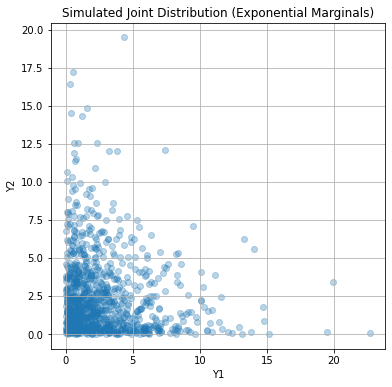

In [ ]:
# Set seed for reproducibility
np.random.seed(42)

# Number of samples
n = 10000

# Step 1: Generate uniform covariates X1 and X2
X1 = np.random.uniform(0, 1, n)
X2 = np.random.uniform(0, 1, n)

# Step 2: Define functions for dependence and marginal parameters
def theta_func(x1, x2):
    # Map to [-1, 1]
    return np.tanh(2 * x1 - x2)

def mean1_func(x1, x2):
    # Mean must be >0 for exponential
    return 1.0 + 2.0 * x1 + np.abs(np.sin(2 * np.pi * x2))

def mean2_func(x1, x2):
    return 1.0 + 1.5 * x2 + np.abs(np.cos(2 * np.pi * x1))

# Step 3: Sample from FGM copula

# Sample independent U, V from Uniform(0, 1)
U = np.random.uniform(0, 1, n)
V_indep = np.random.uniform(0, 1, n)

# Compute theta values
theta_vals = theta_func(X1, X2)

# Apply FGM copula transformation
V = V_indep + theta_vals * V_indep * (1 - V_indep) * (1 - 2 * U)

# Clip to [0,1] to ensure valid inputs to inverse CDF
U = np.clip(U, 1e-10, 1 - 1e-10)
V = np.clip(V, 1e-10, 1 - 1e-10)

# Step 4: Transform to Exponential marginals

mean1_vals = mean1_func(X1, X2)
mean2_vals = mean2_func(X1, X2)

# In scipy, expon.ppf takes a "scale" parameter = mean
Y1 = expon.ppf(U, loc=0, scale=mean1_vals)
Y2 = expon.ppf(V, loc=0, scale=mean2_vals)

# ✅ Done! Y1 and Y2 are sampled from exponential marginals linked by FGM copula.

# Optional: plot a sample
plt.figure(figsize=(6, 6))
plt.scatter(Y1[:1000], Y2[:1000], alpha=0.3)
plt.title("Simulated Joint Distribution (Exponential Marginals)")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()


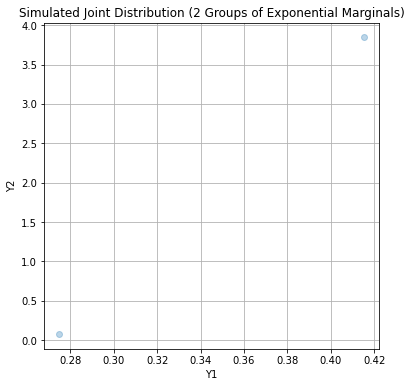

In [15]:
import numpy as np
from scipy.stats import expon
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(42)

# Number of samples
n = 2

# Step 1: Generate uniform covariates X1 and X2
X1 = np.random.uniform(0, 1, n)
X2 = np.random.uniform(0, 1, n)

# Step 2: Define logical mask for group split
group_A = (X1 + X2 < 1)
group_B = ~group_A  # Complement of A

# Step 3: Define group-specific functions

def theta_A(x1, x2):
    return 0.8 * np.tanh(x1 - x2)

def theta_B(x1, x2):
    return -0.6 * np.tanh(2 * x2 - x1)

def mean1_A(x1, x2):
    return 1.0 + x1 + 2 * x2

def mean1_B(x1, x2):
    return 2.0 + np.sin(3 * np.pi * x1)

def mean2_A(x1, x2):
    return 1.5 + np.abs(np.cos(2 * np.pi * x2))

def mean2_B(x1, x2):
    return 0.8 + 1.2 * x2 + 0.5 * x1

# Step 4: Sample from FGM copula

U = np.random.uniform(0, 1, n)
V_indep = np.random.uniform(0, 1, n)

# Initialize theta array
theta = np.empty(n)

# Fill with group-specific theta
theta[group_A] = theta_A(X1[group_A], X2[group_A])
theta[group_B] = theta_B(X1[group_B], X2[group_B])

# FGM copula transformation
V = V_indep + theta * V_indep * (1 - V_indep) * (1 - 2 * U)
U = np.clip(U, 1e-10, 1 - 1e-10)
V = np.clip(V, 1e-10, 1 - 1e-10)

# Step 5: Transform to Exponential marginals with group-specific means

mean1 = np.empty(n)
mean2 = np.empty(n)

mean1[group_A] = mean1_A(X1[group_A], X2[group_A])
mean1[group_B] = mean1_B(X1[group_B], X2[group_B])

mean2[group_A] = mean2_A(X1[group_A], X2[group_A])
mean2[group_B] = mean2_B(X1[group_B], X2[group_B])

Y1 = expon.ppf(U, scale=mean1)
Y2 = expon.ppf(V, scale=mean2)

# ✅ Done!

# Optional: visualize samples
plt.figure(figsize=(6, 6))
plt.scatter(Y1[:1000], Y2[:1000], alpha=0.3)
plt.title("Simulated Joint Distribution (2 Groups of Exponential Marginals)")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()


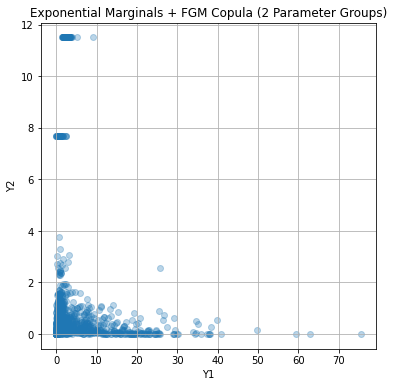

In [9]:
import numpy as np
from scipy.stats import expon
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(42)

# Number of samples
n = 100_000

# Step 1: Covariates
X1 = np.random.uniform(0, 1, n)
X2 = np.random.uniform(0, 1, n)

# Step 2: Group assignment
group_A = (X1 + X2 < 1)
group_B = ~group_A

# Step 3: Assign parameters by group
theta = np.zeros(n)
mean1 = np.zeros(n)
mean2 = np.zeros(n)

# Group A parameters
theta[group_A] = -2.0
mean1[group_A] = 1.0       # rate = 1
mean2[group_A] = 0.5       # rate = 2

# Group B parameters
theta[group_B] = 2.0
mean1[group_B] = 10.0       # rate = 0.5
mean2[group_B] = 1/3       # rate = 3

# Step 4: FGM copula sampling
U = np.random.uniform(0, 1, n)
V_indep = np.random.uniform(0, 1, n)

V = V_indep + theta * V_indep * (1 - V_indep) * (1 - 2 * U)
U = np.clip(U, 1e-10, 1 - 1e-10)
V = np.clip(V, 1e-10, 1 - 1e-10)

# Step 5: Exponential marginals
Y1 = expon.ppf(U, scale=mean1)
Y2 = expon.ppf(V, scale=mean2)

# ✅ Done. Y1 and Y2 follow exponential marginals with FGM copula dependence.

# Optional: visualize
plt.figure(figsize=(6, 6))
plt.scatter(Y1[:1000], Y2[:1000], alpha=0.3)
plt.title("Exponential Marginals + FGM Copula (2 Parameter Groups)")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()


In [10]:
x = np.vstack((X1, X2)).T
y = np.vstack((Y1, Y2)).T
#print(x)
#print(y)
#print(mean1_func(x[:,0], x[:,1]))
#print(mean2_func(x[:,0], x[:,1]))
#print(theta_func(x[:,0], x[:,1]))

m = MBT(loss_type = "copula", n_boosts = 3, min_leaf = 100, refit=False).fit(x, y, do_plot=False)

  0%|          | 0/3 [00:00<?, ?it/s]

[-1.77591453e-16 -4.95985416e-16 -5.40733871e-02]


 33%|███▎      | 1/3 [00:01<00:02,  1.08s/it]

[-1.77591453e-16 -4.95985416e-16 -4.86451355e-02]


 67%|██████▋   | 2/3 [00:01<00:00,  1.03it/s]

[-1.77591453e-16 -2.95051501e-16 -4.37712048e-02]


100%|██████████| 3/3 [00:02<00:00,  1.01it/s]

#---------------- Model fitted in 4.94e-02 min ----------------


In [11]:
#print(mean1_func(x[:,0], x[:,1]))
#print(mean2_func(x[:,0], x[:,1]))
#print(theta_func(x[:,0], x[:,1]))

In [ ]:
tpar = m.predict(x, n=3)

In [18]:
loss = CopulaLikelihood()
par = np.hstack((np.exp(tpar[:,0].reshape(-1, 1)), np.exp(tpar[:,1].reshape(-1,1)), loss.fgm_par_inv_link(tpar[:,2].reshape(-1,1))))

In [23]:
#print(mean1_func(x[30,0], x[30,1]))
#print(mean2_func(x[30,0], x[30,1]))
#print(theta_func(x[30,0], x[30,1]))
print(par[1,:])
print(np.all(par == par[0,:], axis=1).all())

[ 2.84491401  0.48440851 -0.17046037]
False
